<h1 align="center">Used Car Price Prediction</h1> 

<h3 align="center">Linear Regression</h3> 

---------------------------------------------------------------------------------------------------------------------------

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
import warnings
warnings.filterwarnings('ignore')

In [2]:
# loading the data
car = pd.read_csv("Data/Car_preproccesed.csv")

In [3]:
car.head()

,log_price,Mileage,EngineV,Brand_BMW,Brand_Mercedes-Benz,Brand_Mitsubishi,Brand_Renault,Brand_Toyota,Brand_Volkswagen,Body_hatch,Body_other,Body_sedan,Body_vagon,Body_van,Engine Type_Gas,Engine Type_Other,Engine Type_Petrol,Registration_yes
0,8.342840,277,2.0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,1
1,8.974618,427,2.9,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1
2,9.495519,358,5.0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,1
3,10.043249,240,4.2,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1
4,9.814656,120,2.0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,1


In [ ]:
# Declaring the feature and target variable
X = car.drop('log_price', axis=1)
y = car['log_price']

In [5]:
X.shape , y.shape

((3867, 17), (3867,))

### Scaling the data

In [6]:
from sklearn.preprocessing import StandardScaler

# create instance of scaler
scaler = StandardScaler()

# scaling the data
X_scaled = scaler.fit_transform(X)

In [7]:
X_scaled

array([[ 1.2179077 , -0.47452478,  2.27971827, ..., -0.16209221,
         1.33267512,  0.32137366],
       [ 2.78660201,  0.47359854, -0.43865069, ..., -0.16209221,
        -0.75037043,  0.32137366],
       [ 2.06500263,  2.68588629, -0.43865069, ..., -0.16209221,
        -0.75037043,  0.32137366],
       ...,
       [-1.58482613,  0.57894557, -0.43865069, ..., -0.16209221,
        -0.75037043,  0.32137366],
       [-1.66848982,  1.10568075,  2.27971827, ..., -0.16209221,
         1.33267512,  0.32137366],
       [-0.38216049, -0.47452478, -0.43865069, ..., -0.16209221,
        -0.75037043,  0.32137366]])

### train_test_spilit

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42)

In [9]:
X_train.shape, y_train.shape, X_test.shape, y_test.shape

((3093, 17), (3093,), (774, 17), (774,))

### Apply Linear Regression

In [10]:
from sklearn.linear_model import LinearRegression

# create instance of model
reg = LinearRegression()

model = reg.fit(X_train, y_train)

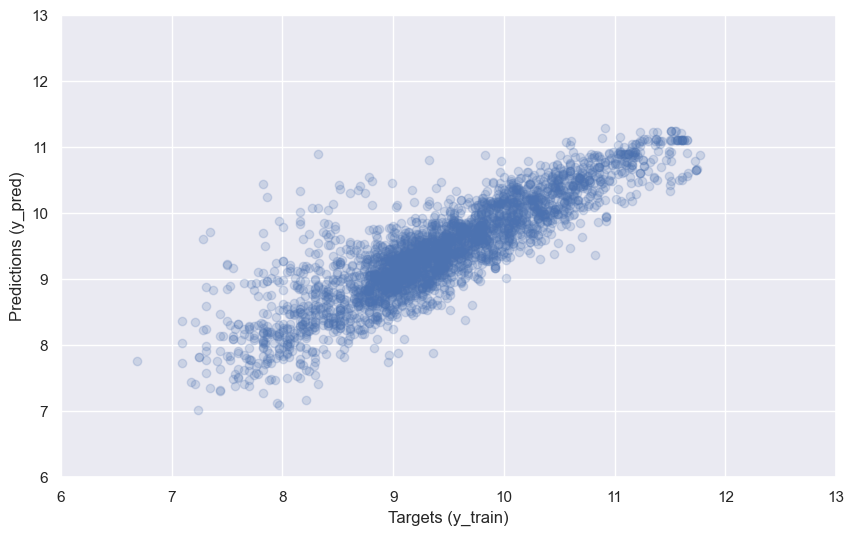

In [11]:
# Evaluate the base Linear regression model

# checking how well the model learned the training patterns.
y_pred_train = reg.predict(X_train)

plt.figure(figsize=(10,6))
plt.scatter(y_train, y_pred_train, alpha=0.2);
plt.xlabel('Targets (y_train)');
plt.ylabel('Predictions (y_pred)');
plt.xlim(6,13);
plt.ylim(6,13);

The traning prediction looks good, it is not completely random, i can observe the linearity on the plot

Another way to check the `Residual` which is difference between the targets and the predictions.

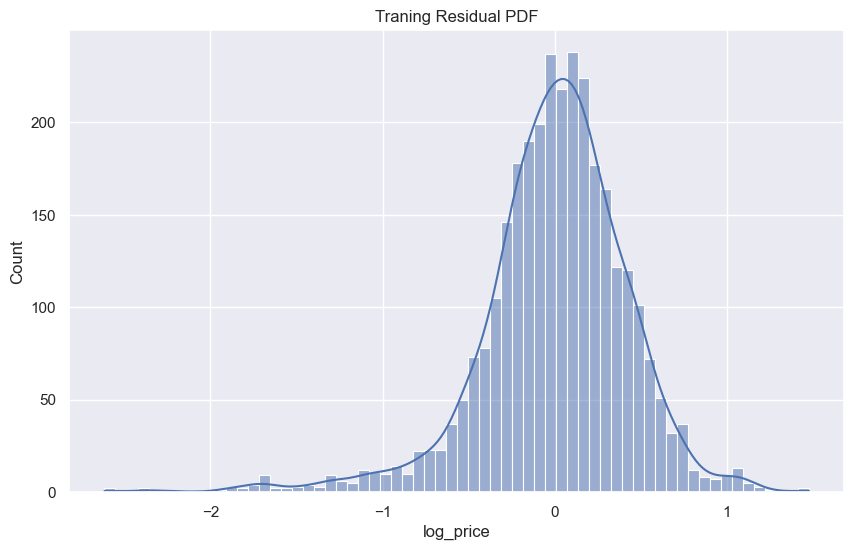

In [13]:
# calculate residuals
residual_train = (y_train - y_pred_train)

# plot residual distribution
plt.figure(figsize=(10,6))
sns.histplot(residual_train, kde=True);
plt.title('Traning Residual PDF');

- From this plot I can observe that the most of the value are lie on the near `0` as the mean is `0` , that means the model is worked better, as most of the difference is `0`, the model is make the prediction as it is on the target value.

In [14]:
# Checking the r2_score
from sklearn.metrics import r2_score

r2_score(y_train, y_pred_train)

0.7546487921881216

In [15]:
#checking the rmse
from sklearn.metrics import mean_squared_error

np.sqrt(mean_squared_error(np.exp(y_train), np.exp(y_pred_train)))

np.float64(10130.478739873179)

The minimum and maximum car prices in the dataset were `800` and `129222`, and the model produces an average prediction error of around `10165`.

The model I created is not excellent, but also not that much bad.

Model is defining 75% of the variability from the data.

### Now i will look at the weight and bias


In [17]:
reg_summary = pd.DataFrame(X.columns.values, columns=['Features'])
reg_summary['Weights'] = reg.coef_
reg_summary

,Features,Weights
0,Mileage,-0.468156
1,EngineV,0.215268
2,Brand_BMW,0.011052
3,Brand_Mercedes-Benz,0.005692
4,Brand_Mitsubishi,-0.142472
5,Brand_Renault,-0.187693
6,Brand_Toyota,-0.065297
7,Brand_Volkswagen,-0.098989
8,Body_hatch,-0.139808
9,Body_other,-0.093845


#### Model Interpretation

Now this will not be a fully **generalized model** because I violated a rule by **scaling the dummy variables**.  

However, here I will explain the **weights obtained from the model**.

- **Positive weights** → When the feature value increases, the **predicted price also increases**.

- **Negative weights** → When the feature value increases, the **predicted price decreases**.

### Now evaluate on Testing data

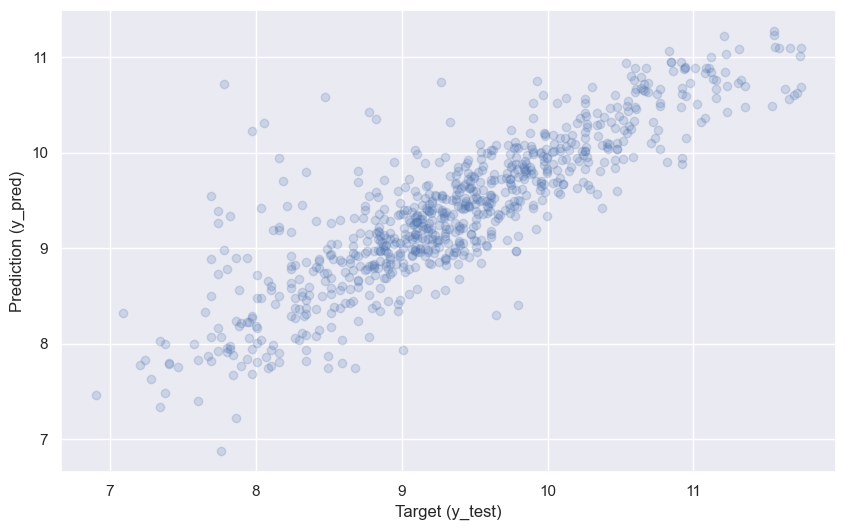

In [18]:
y_pred = reg.predict(X_test)

# potting the graph
plt.figure(figsize=(10,6))
plt.scatter(y_test, y_pred, alpha=0.2);

plt.xlabel('Target (y_test)');
plt.ylabel('Prediction (y_pred)');

In [19]:
# checking the rmse on test data
np.sqrt(mean_squared_error(np.exp(y_test), np.exp(y_pred)))

np.float64(11311.881290679337)

On the test data, the model produces an average prediction error of around `11311`.

This indicates that the model performance is not very good, but it is also not overfitting because the model behaves similarly on both the training and testing data.

In [20]:
# Creating a dataframe to compare the result and prediction.
df_eval = pd.DataFrame(np.exp(y_pred), columns=['Prediction']) # np.exp will reverse the log_tranformation 

# adding column
y_test = y_test.reset_index(drop=True)
df_eval['Target'] = np.exp(y_test)

# checking the performance data 
df_eval

,Prediction,Target
0,40419.308971,21300.0
1,7956.895960,8900.0
2,5757.284408,3250.0
3,9765.810605,12000.0
4,7027.363814,5400.0
...,...,...
769,4699.586013,4200.0
770,9123.067372,8800.0
771,6267.803094,4850.0
772,20906.128600,27000.0


In [22]:
df_eval['Residual'] = df_eval['Target'] - df_eval['Prediction']
df_eval['Difference%'] = np.absolute(df_eval['Residual'] / df_eval['Target']*100)

# checking the data performance
df_eval

,Prediction,Target,Residual,Difference%
0,40419.308971,21300.0,-19119.308971,89.762014
1,7956.895960,8900.0,943.104040,10.596675
2,5757.284408,3250.0,-2507.284408,77.147213
3,9765.810605,12000.0,2234.189395,18.618245
4,7027.363814,5400.0,-1627.363814,30.136367
...,...,...,...,...
769,4699.586013,4200.0,-499.586013,11.894905
770,9123.067372,8800.0,-323.067372,3.671220
771,6267.803094,4850.0,-1417.803094,29.233053
772,20906.128600,27000.0,6093.871400,22.569894


In [23]:
df_eval.describe()

,Prediction,Target,Residual,Difference%
count,774.000000,774.000000,774.000000,774.000000
mean,16113.011638,17799.988992,1686.977355,42.085282
std,13326.229797,19723.434542,11192.614496,96.169928
min,967.030415,999.000000,-42859.020603,0.020246
25%,7467.591694,6700.000000,-2246.354353,11.024941
50%,11914.358989,11050.000000,-38.697776,24.086183
75%,20249.505640,20475.000000,3004.524837,42.381716
max,79026.348020,125000.000000,81051.158885,1785.792525


In [24]:
# getting all values.
pd.options.display.max_rows = 999

# setting all values to two digits after decimal
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# sorting the dataframe by percentage difference
df_eval.sort_values(by=['Difference%'])

,Prediction,Target,Residual,Difference%
387,13602.75,13600.00,-2.75,0.02
74,28889.06,28900.00,10.94,0.04
314,35530.21,35500.00,-30.21,0.09
336,11313.27,11300.00,-13.27,0.12
425,2995.68,3000.00,4.32,0.14
262,52180.11,52055.25,-124.86,0.24
674,3107.51,3100.00,-7.51,0.24
648,9675.57,9700.00,24.43,0.25
79,21407.59,21335.00,-72.59,0.34
313,9865.72,9900.00,34.28,0.35


The note here is that the higher difference mostly occurs on the lower-priced cars.

As I can see, the residuals are mostly negative, which means the model is predicting values far higher than the original prices.

As I observed in the `Residual PDF` plot, the tail was on the negative side. This table is a more tabular representation of that behavior.

It is telling me that I am missing some important information because the actual price of the car is lower, but my model still thinks it should be higher.

It may be because of the `Model` column that I removed during the initial stage, or maybe the car is damaged or broken, but that information is not available in the dataset.

#### The next thing is creating another model and keep the `Model` Column